# Task 3: Guest booking segments

K-means groups bookings using information available at booking time. The scaler, clipping limits and cluster model use only arrivals through December 2016, so the resulting segment can be used safely in later time-based models.


In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
SLIDE_DIR = Path('../slides')
MODEL_DIR = Path('../models')
for folder in [DATA_DIR, OUTPUT_DIR, SLIDE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [2]:
df = pd.read_csv(DATA_DIR / 'hotel_bookings_clean.csv', parse_dates=['arrival_date'])
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['weekend_share'] = np.where(df['total_nights'].gt(0), df['stays_in_weekend_nights'] / df['total_nights'], 0)

cluster_features = [
    'lead_time','total_nights','total_guests','weekend_share',
    'is_repeated_guest','previous_cancellations',
    'previous_bookings_not_canceled','required_car_parking_spaces'
]
train_mask = df['arrival_date'].lt('2017-01-01')
train_x = df.loc[train_mask, cluster_features].astype(float).copy()
all_x = df[cluster_features].astype(float).copy()

clip_limits = {}
for col in cluster_features:
    low, high = train_x[col].quantile([0.01, 0.99])
    clip_limits[col] = [float(low), float(high)]
    train_x[col] = train_x[col].clip(low, high)
    all_x[col] = all_x[col].clip(low, high)

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_x)
all_scaled = scaler.transform(all_x)
print('Training rows:', len(train_x), 'Features:', cluster_features)


Training rows: 78590 Features: ['lead_time', 'total_nights', 'total_guests', 'weekend_share', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'required_car_parking_spaces']


## Number of clusters

The notebook compares inertia and silhouette scores for K=2 through K=7. Silhouette uses a fixed random sample to keep the run reproducible.


   k        inertia  silhouette
0  2  507041.882908    0.626775
1  3  429009.732584    0.426013
2  4  355158.243048    0.459343
3  5  298499.557442    0.271818
4  6  261571.729410    0.295203
5  7  229756.740099    0.320574


   k        inertia  silhouette
0  2  507041.882908    0.626775
1  3  429009.732584    0.426013
2  4  355158.243048    0.459343
3  5  298499.557442    0.271818
4  6  261571.729410    0.295203
5  7  229756.740099    0.320574

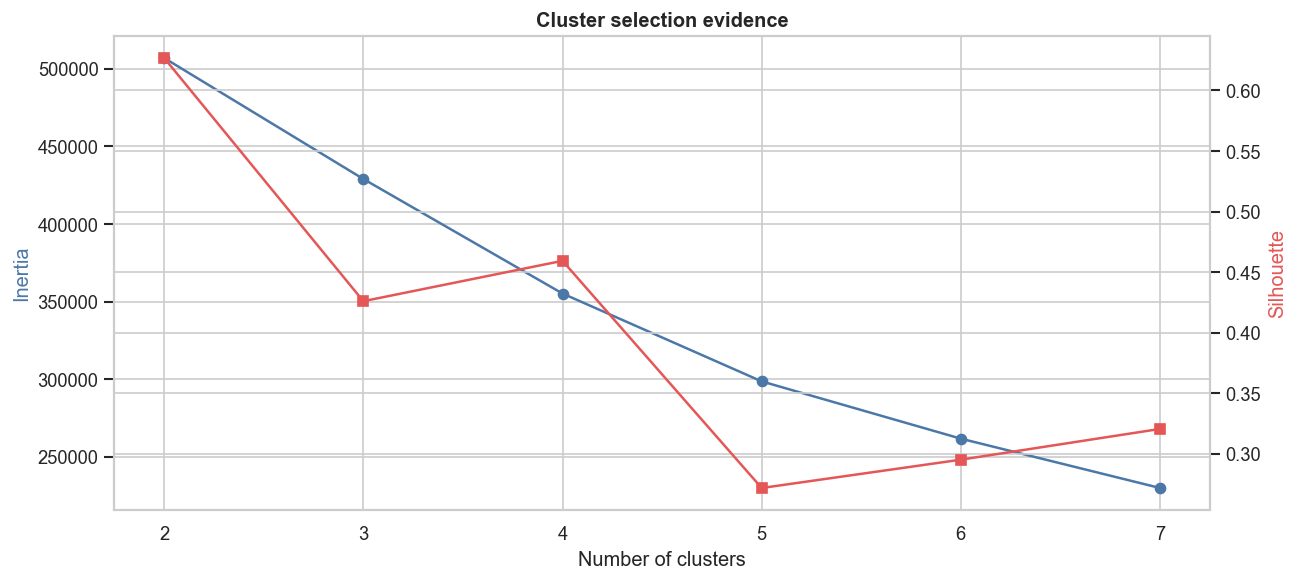

In [3]:
sample_rng = np.random.RandomState(SEED)
sample_idx = sample_rng.choice(len(train_scaled), size=min(20000, len(train_scaled)), replace=False)
k_rows = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = km.fit_predict(train_scaled)
    score = silhouette_score(train_scaled[sample_idx], labels[sample_idx])
    k_rows.append({'k':k, 'inertia':km.inertia_, 'silhouette':score})
k_results = pd.DataFrame(k_rows)
display(k_results)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()
ax1.plot(k_results['k'], k_results['inertia'], marker='o', color='#4C78A8')
ax2.plot(k_results['k'], k_results['silhouette'], marker='s', color='#E45756')
ax1.set_xlabel('Number of clusters'); ax1.set_ylabel('Inertia', color='#4C78A8'); ax2.set_ylabel('Silhouette', color='#E45756')
ax1.set_title('Cluster selection evidence', fontweight='bold')
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'cluster_selection.png', bbox_inches='tight'); plt.show()


## Final four-segment model

Four segments keep the actions understandable while retaining separation across booking horizon, stay pattern and loyalty. The score is reported alongside the best statistical option rather than hidden.


         bookings  lead_time  nights  ...  cancellation_rate  median_adr  share
cluster                               ...                                      
0          102917       72.0     3.0  ...              0.371       96.00  0.863
1            3798        3.0     1.0  ...              0.087       65.00  0.032
2            6771       24.0     3.0  ...              0.000      104.06  0.057
3            5723      259.0     2.0  ...              0.997       68.00  0.048

[4 rows x 11 columns]
                      cluster_name  ...                                             action
cluster                             ...                                                   
0                 Long-stay guests  ...  Offer stay extensions and review revenue expos...
1              Loyal repeat guests  ...  Protect loyalty benefits and avoid unnecessary...
2        Short-lead standard stays  ...  Use quick confirmation and availability-based ...
3                   Early planners  ...  S

         bookings  lead_time  nights  ...  cancellation_rate  median_adr  share
cluster                               ...                                      
0          102917       72.0     3.0  ...              0.371       96.00  0.863
1            3798        3.0     1.0  ...              0.087       65.00  0.032
2            6771       24.0     3.0  ...              0.000      104.06  0.057
3            5723      259.0     2.0  ...              0.997       68.00  0.048

[4 rows x 11 columns]

                      cluster_name  ...                                             action
cluster                             ...                                                   
0                 Long-stay guests  ...  Offer stay extensions and review revenue expos...
1              Loyal repeat guests  ...  Protect loyalty benefits and avoid unnecessary...
2        Short-lead standard stays  ...  Use quick confirmation and availability-based ...
3                   Early planners  ...  Schedule confirmation reminders well before ar...

[4 rows x 8 columns]

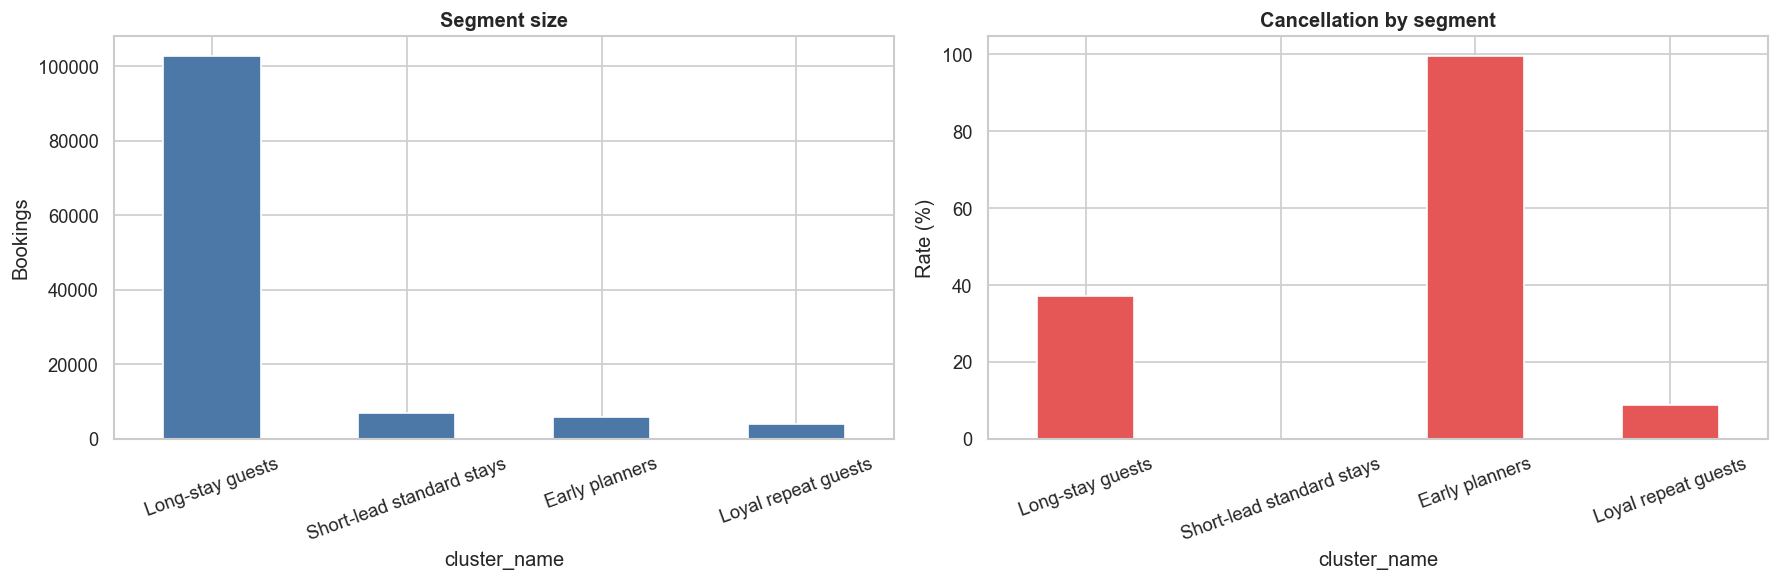

In [4]:
K_FINAL = 4
kmeans = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=30)
kmeans.fit(train_scaled)
df['cluster'] = kmeans.predict(all_scaled)

profile = df.groupby('cluster').agg(
    bookings=('source_row_id','size'),
    lead_time=('lead_time','median'),
    nights=('total_nights','median'),
    guests=('total_guests','median'),
    weekend_share=('weekend_share','mean'),
    repeated_rate=('is_repeated_guest','mean'),
    prior_cancellations=('previous_cancellations','mean'),
    parking_rate=('required_car_parking_spaces', lambda x: (x > 0).mean()),
    cancellation_rate=('is_canceled','mean'),
    median_adr=('adr','median'),
)
profile['share'] = profile['bookings'] / len(df)
display(profile.round(3))

# Names are assigned from the measured profile, not from cluster numbers alone.
names = {}
remaining = set(profile.index)
loyal = profile['repeated_rate'].idxmax(); names[loyal] = 'Loyal repeat guests'; remaining.remove(loyal)
early = profile.loc[list(remaining), 'lead_time'].idxmax(); names[early] = 'Early planners'; remaining.remove(early)
longstay = profile.loc[list(remaining), 'nights'].idxmax(); names[longstay] = 'Long-stay guests'; remaining.remove(longstay)
last = list(remaining)[0]; names[last] = 'Short-lead standard stays'
df['cluster_name'] = df['cluster'].map(names)
profile['cluster_name'] = profile.index.map(names)

actions = {
    'Loyal repeat guests': 'Protect loyalty benefits and avoid unnecessary deposit requests.',
    'Early planners': 'Schedule confirmation reminders well before arrival.',
    'Long-stay guests': 'Offer stay extensions and review revenue exposure before discounting.',
    'Short-lead standard stays': 'Use quick confirmation and availability-based pricing.'
}
profile['action'] = profile['cluster_name'].map(actions)
display(profile[['cluster_name','bookings','share','lead_time','nights','repeated_rate','cancellation_rate','action']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ordered = profile.set_index('cluster_name').sort_values('bookings', ascending=False)
ordered['bookings'].plot.bar(ax=axes[0], color='#4C78A8')
ordered['cancellation_rate'].mul(100).plot.bar(ax=axes[1], color='#E45756')
axes[0].set_title('Segment size', fontweight='bold'); axes[0].set_ylabel('Bookings')
axes[1].set_title('Cancellation by segment', fontweight='bold'); axes[1].set_ylabel('Rate (%)')
for ax in axes: ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'cluster_profiles_final.png', bbox_inches='tight'); plt.show()

df.to_csv(DATA_DIR / 'hotel_bookings_clustered.csv', index=False)
profile.to_csv(OUTPUT_DIR / 'cluster_summary.csv')
(MODEL_DIR / 'cluster_config.json').write_text(json.dumps({
    'features': cluster_features, 'clip_limits': clip_limits, 'k': K_FINAL,
    'train_end': '2016-12-31', 'random_state': SEED,
}, indent=2), encoding='utf-8')
print('Saved clustered data and segment summary.')
